In [1]:
import sgp
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Computer Modern'],
    'axes.labelsize': 12,   # Font size for axis labels
    'font.size': 12,        # General font size
    'legend.fontsize': 12,  # Font size for legend
    'xtick.labelsize': 12,  # Font size for x-axis tick labels
    'ytick.labelsize': 12   # Font size for y-axis tick labels
})
plt.rcParams["figure.figsize"] = (4, 3)
plt.rc('text', usetex=True)
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath,amssymb,bm}'

In [2]:
nx = 2**7
ny = 2**7

lx = 30
ly = 30

dt = 2e-4

# Chemical potential schedule
def mu_fun(t, tau, mu_i=0.1, mu_f=20.0, t_r=10):
    return mu_i*(t<=t_r) + (mu_i + (mu_f - mu_i) * (t-t_r) / tau)*(t>t_r)*(t<=(t_r+tau)) + mu_f * (t>(t_r+tau))

geo = sgp.Geometry(N=(nx, ny), L=(lx, ly))
dispersion = (geo.kx_**2 + geo.ky_**2) / 2

syst = sgp.System(g_2d=1.0, spin_g_factor=0.5, gamma=0.03, temp=1)
syst.set_geometry(geo)
syst.set_dispersion(dispersion)

psi1_initial = 0e-2 * (np.random.default_rng(1).normal(size=(ny, ny)) + 1j * np.random.default_rng(1).normal(size=(nx, ny)))
psi2_initial = 0e-2 * (np.random.default_rng(2).normal(size=(ny, ny)) + 1j * np.random.default_rng(2).normal(size=(nx, ny)))


In [3]:
psi1_t, psi2_t = syst.evolve(psi1_0=psi1_initial,
                    psi2_0=psi2_initial,
                    n_steps=550000,
                    dt=2e-4,
                    e_cut=50,
                    mu=mu_fun,
                    snapshots=500,
                    tau=100,
                    mu_i=0.1,
                    mu_f=20.0,
                    t_r=10)

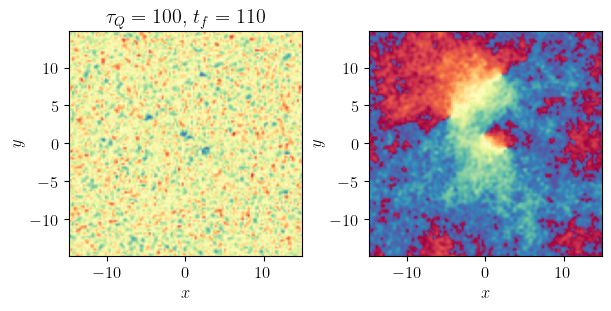

In [4]:
# ----------------------- plot final density -----------------------
fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)

# plt.figure(figsize=(6,5))
im1 = ax[0].pcolormesh(geo.x, geo.y, np.abs(psi1_t[-1])**2, cmap='Spectral_r', shading='gouraud')
im2 = ax[1].pcolormesh(geo.x, geo.y, np.angle(psi1_t[-1]), cmap='Spectral_r', shading='gouraud')
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$y$")
ax[1].set_xlabel(r"$x$")
ax[1].set_ylabel(r"$y$")
ax[0].set_title(r"$\tau_Q=%.0f$, $t_f=%.0f$" % (100, 550000*2e-4))
# fig.colorbar(im1, label=r"$|\psi(x, y)|^2$")
# fig.colorbar(im2, label=r"$\theta(x, y)$")
# plt.tight_layout()
plt.show()


In [5]:
from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter

t_axis = (np.arange(500)*(550000//499))*dt
# Parameters
n_frames = 500

X, Y = np.meshgrid(geo.x, geo.y)

# --- Set up the figure ---
fig, ax = plt.subplots(1, 2, figsize=(5, 2.5), constrained_layout=True)

im1 = ax[0].pcolormesh(X, Y, np.abs(psi1_t[0])**2, cmap='Spectral_r', shading='gouraud', vmin=0, vmax=35)
im2 = ax[1].pcolormesh(X, Y, np.angle(psi1_t[0]), cmap='Spectral_r', shading='gouraud')

ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$y$")
ax[1].set_xlabel(r"$x$")
ax[1].set_ylabel(r"$y$")
ax[0].set_title(r"$t/\tau_Q=%.4f$" % (t_axis[0]/100))

# --- Update function ---
def update(frame):
    im1.set_array((np.abs(psi1_t[frame])**2).ravel())
    im2.set_array(np.angle(psi1_t[frame]).ravel())
    ax[0].set_title(r"$t/\tau_Q=%.4f$" % (t_axis[frame]/100))
    return im1, im2

# --- Animation ---
anim = FuncAnimation(fig, update, frames=n_frames, blit=True)
writer = FFMpegWriter(fps=24, bitrate=5000, codec='libx264')
# writer = PillowWriter(fps=10)
# --- Save GIF ---
anim.save("psi_evolution_misc.mp4", writer=writer, dpi=300)
plt.close()


In [9]:
np.save('psi1_inmiscible_sample.npy', psi1_t)
np.save('psi2_inmiscible_sample.npy', psi2_t)